# Healthcare Access and Affordability in India
## National Health Accounts: exploratory analysis

This notebook analyses official national health-financing indicators from the National Health Accounts Estimates for India 2023–24 (NHSRC, MoHFW). The latest published NHA observation in this dataset is 2023–24; it is not presented as 2024–25.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path('../Dataset/national_health_accounts_india_2013_14_to_2023_24.csv')
df = pd.read_csv(DATA_PATH)
df

,financial_year,total_health_expenditure_gdp_pct,ghe_share_total_health_expenditure_pct,oope_share_total_health_expenditure_pct,social_security_health_share_total_health_expenditure_pct,private_health_insurance_share_total_health_expenditure_pct,total_health_expenditure_per_capita_current_inr
0,2013-14,4.0,28.6,64.2,6.0,3.4,3638
1,2014-15,3.9,29.0,62.6,5.7,3.7,3826
2,2015-16,3.8,30.6,60.6,6.3,4.2,4116
3,2016-17,3.8,32.4,58.7,7.3,4.7,4381
4,2017-18,3.3,40.8,48.8,9.0,5.8,4297
5,2018-19,3.2,40.6,48.2,9.6,6.6,4470
6,2019-20,3.3,41.4,47.1,9.3,7.0,4863
7,2020-21,3.7,42.8,44.4,8.6,7.3,5436
8,2021-22,3.8,48.0,39.4,8.7,7.4,6602
9,2022-23,3.4,43.7,43.4,9.9,9.2,6373


## 1. Validate the data

Check year coverage, missing values and the latest available observation before interpreting the results.

In [2]:
print('Rows:', len(df))
print('Missing values by column:\n', df.isna().sum())
print('Latest financial year:', df['financial_year'].iloc[-1])
assert df['financial_year'].is_monotonic_increasing
assert df.isna().sum().sum() == 0

Rows: 11
Missing values by column:
 financial_year                                                 0
total_health_expenditure_gdp_pct                               0
ghe_share_total_health_expenditure_pct                         0
oope_share_total_health_expenditure_pct                        0
social_security_health_share_total_health_expenditure_pct      0
private_health_insurance_share_total_health_expenditure_pct    0
total_health_expenditure_per_capita_current_inr                0
dtype: int64
Latest financial year: 2023-24


## 2. Government and out-of-pocket shares

The chart compares the government and household out-of-pocket contributions as shares of total health expenditure. These are financing shares, not measures of the absolute amount spent.

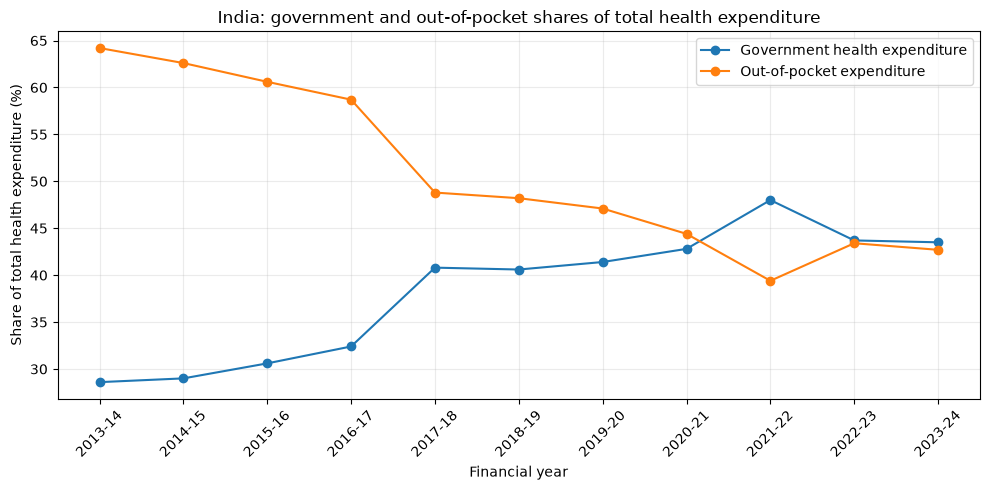

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df['financial_year'], df['ghe_share_total_health_expenditure_pct'], marker='o', label='Government health expenditure')
ax.plot(df['financial_year'], df['oope_share_total_health_expenditure_pct'], marker='o', label='Out-of-pocket expenditure')
ax.set(title='India: government and out-of-pocket shares of total health expenditure', xlabel='Financial year', ylabel='Share of total health expenditure (%)')
ax.tick_params(axis='x', rotation=45)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig('../Visualisations/ghe_vs_oope_share.png', dpi=200, bbox_inches='tight')
plt.show()

## 3. Health expenditure per capita

This series is reported at current prices. It is not inflation-adjusted, so an increase does not by itself indicate an equivalent increase in real healthcare resources.

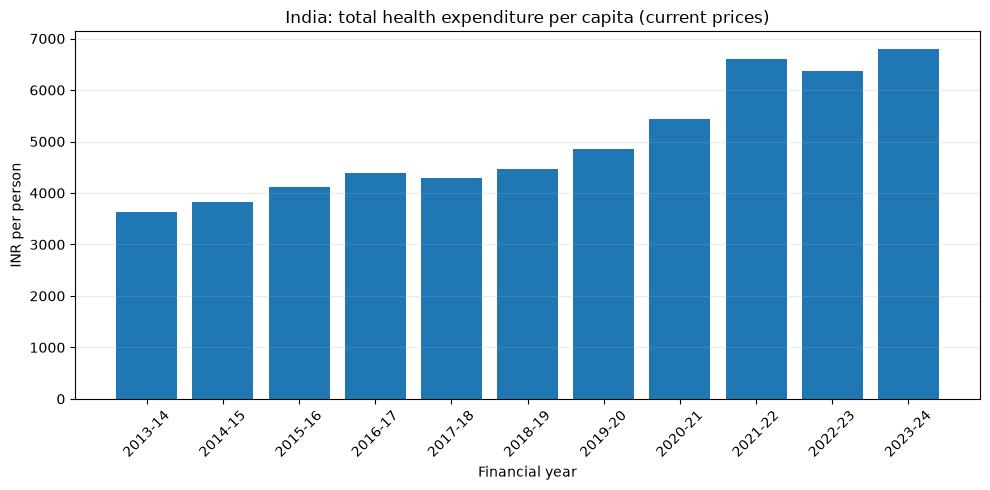

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(df['financial_year'], df['total_health_expenditure_per_capita_current_inr'])
ax.set(title='India: total health expenditure per capita (current prices)', xlabel='Financial year', ylabel='INR per person')
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig('../Visualisations/health_expenditure_per_capita.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Initial descriptive observations

- The out-of-pocket share is lower in 2023–24 than in 2013–14.
- The government share is higher in 2023–24 than in 2013–14.
- Per-capita expenditure is shown at current prices and should not be interpreted as real growth without a deflator.

These are descriptive trends. They do not establish that a particular policy caused the changes.

In [5]:
first, last = df.iloc[0], df.iloc[-1]
print(f"OOPE share: {first['oope_share_total_health_expenditure_pct']:.1f}% ({first['financial_year']}) to {last['oope_share_total_health_expenditure_pct']:.1f}% ({last['financial_year']}).")
print(f"Government share: {first['ghe_share_total_health_expenditure_pct']:.1f}% ({first['financial_year']}) to {last['ghe_share_total_health_expenditure_pct']:.1f}% ({last['financial_year']}).")
print(f"Latest NHA year in this official series: {last['financial_year']}.")

OOPE share: 64.2% (2013-14) to 42.7% (2023-24).
Government share: 28.6% (2013-14) to 43.5% (2023-24).
Latest NHA year in this official series: 2023-24.
